# Quantifying ammonia in the five-hour electrolysis

This example follows the salicylate workflow from blank-corrected absorbance to ammonia concentration, endpoint recovery, Faradaic efficiency, and average production rate. The repository contains the assay signals, calibration points, water-blank spectra, and run configuration for this experiment. The example starts from the deposited assay signals.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "styles" / "manuscript.mplstyle").is_file()
     and (path / "src" / "extended_operation.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Start Jupyter from the repository or its notebooks folder.")

sys.path.insert(0, str(root))
from src.extended_operation import read_inputs, run_extended_operation

style = root / "styles" / "manuscript.mplstyle"
use_tex = False  # Set to True if the manuscript's LaTeX dependencies are installed.
config, standards, _, _, _ = read_inputs(root)
result = run_extended_operation(root)
summary = result["summary"]

## Calibration

The analysis fits low- and high-range standards by unweighted linear regression with a free intercept. Both curves are shown below. These were used for the five-hour experiment's calibration series.

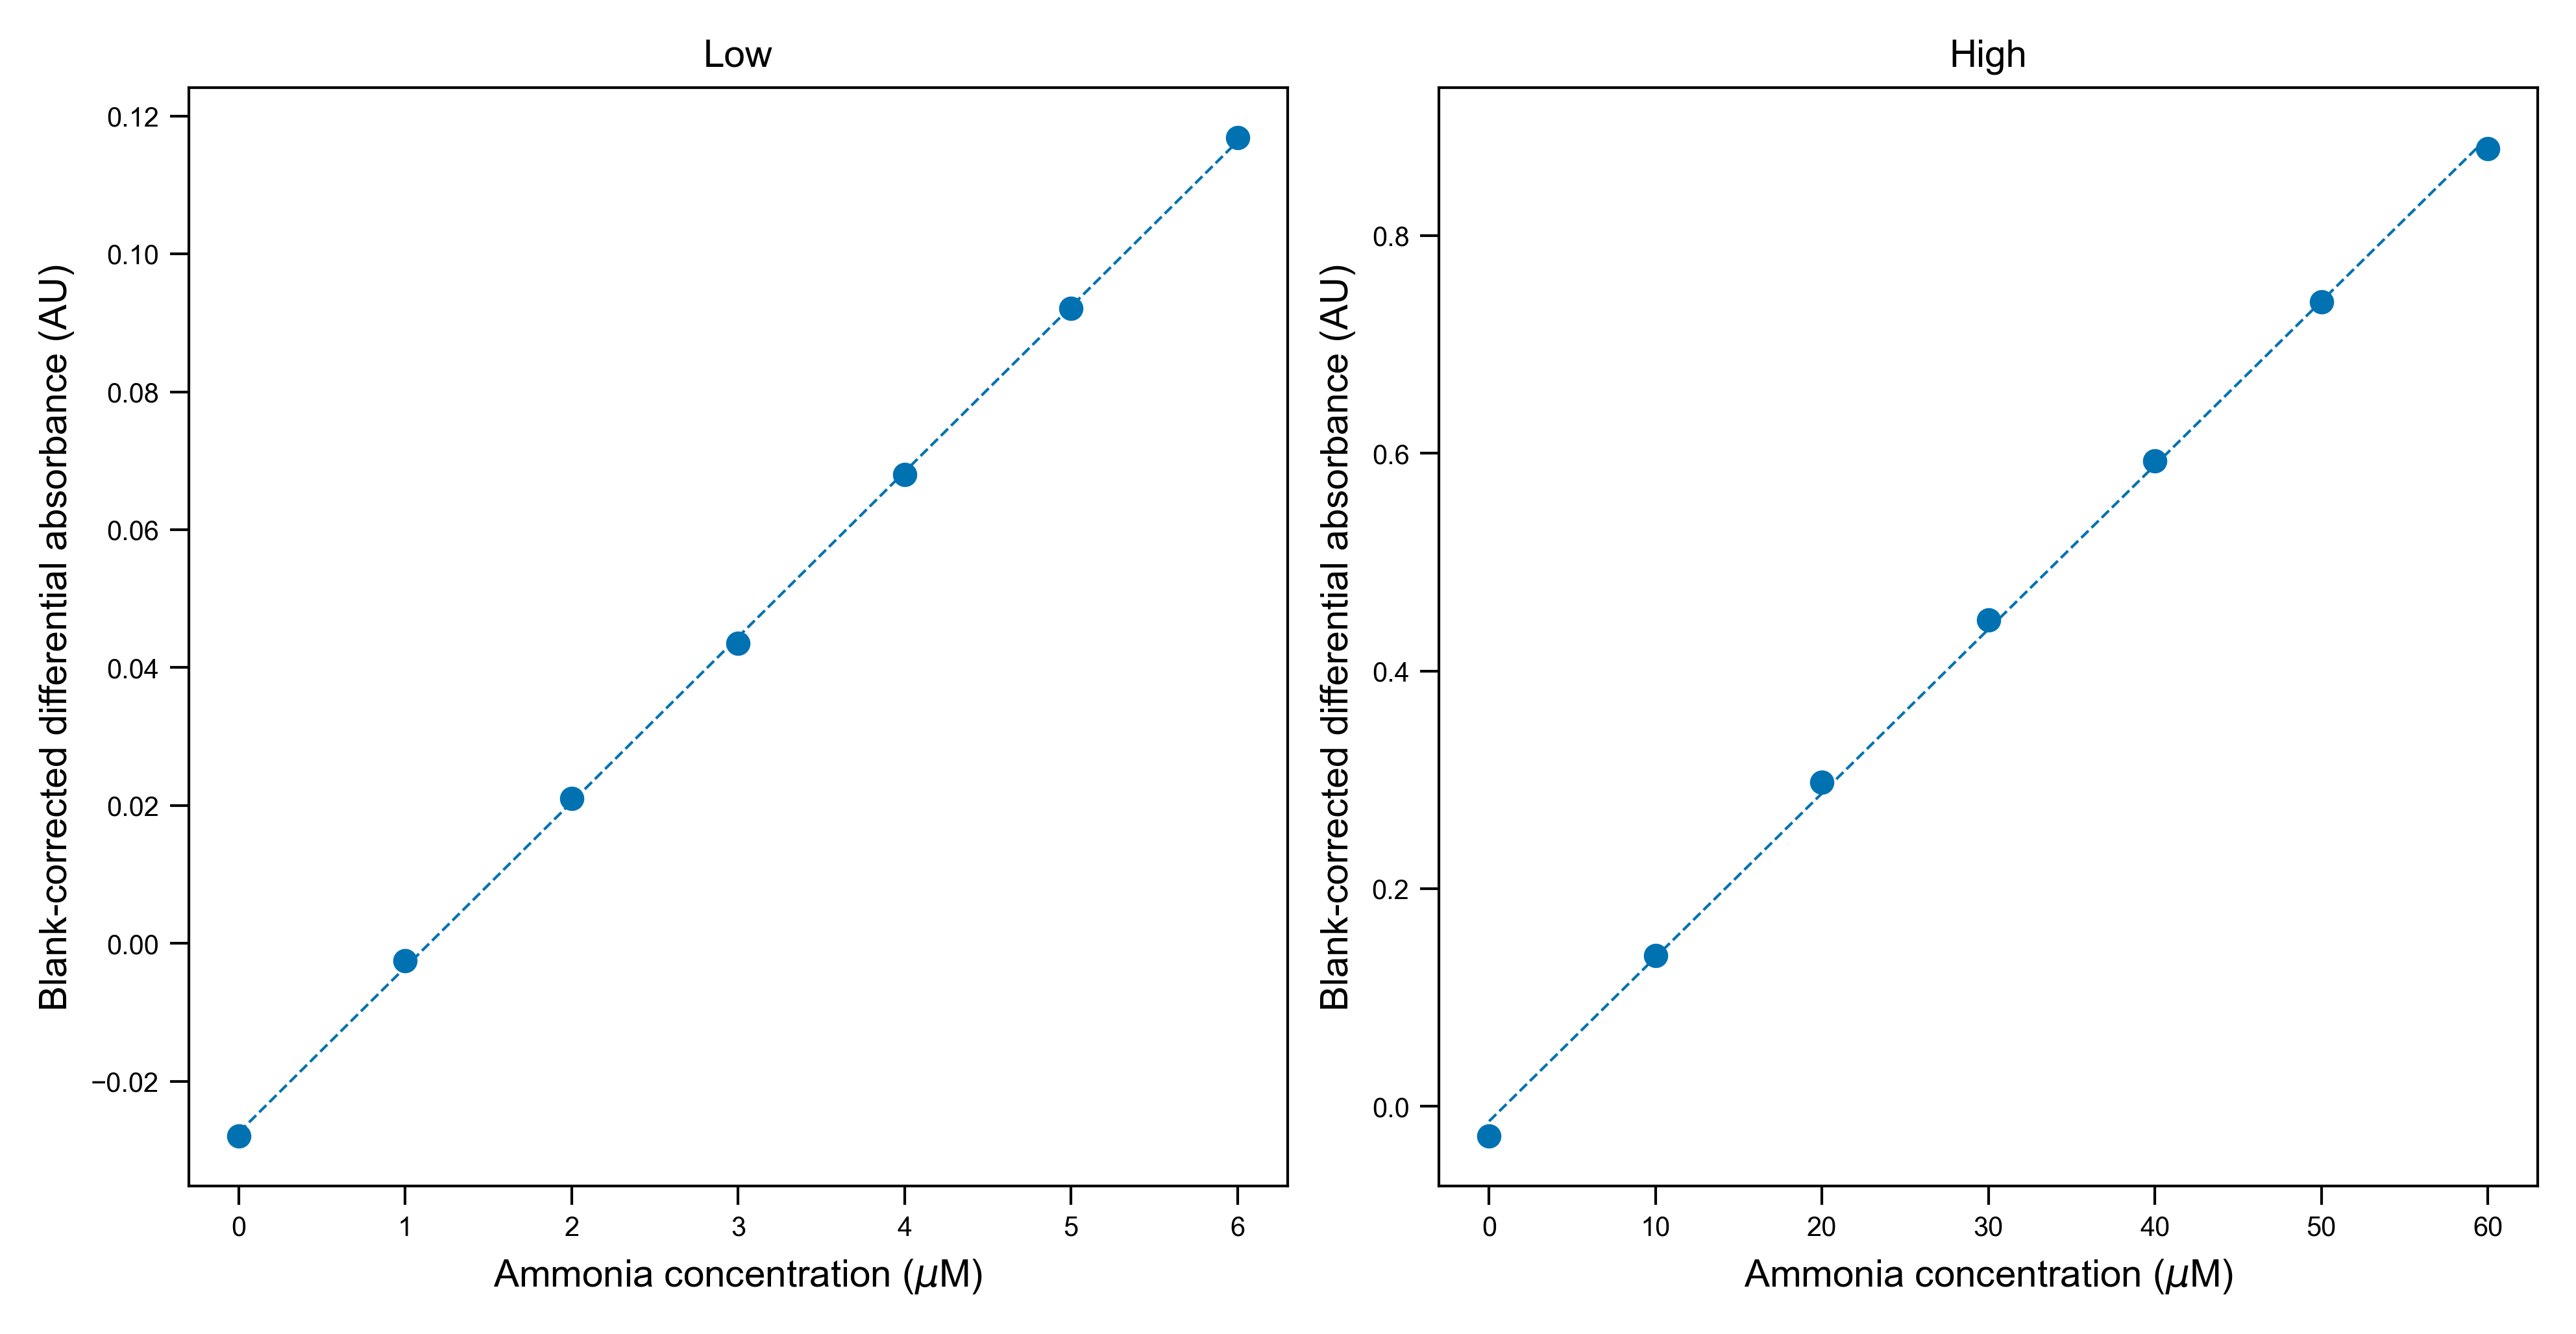

In [2]:
with plt.style.context(style):
    plt.rcParams["text.usetex"] = use_tex
    fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.25), layout="constrained")
    for ax, (name, fit) in zip(axes, summary["calibration_fits"].items()):
        x, y = zip(*fit["data"])
        fitted = [fit["intercept"] + fit["slope"] * value for value in x]
        ax.scatter(x, y)
        ax.plot(x, fitted, linestyle="--")
        ax.set(xlabel=r"Ammonia concentration ($\mu$M)",
               ylabel="Blank-corrected differential absorbance (AU)", title=name.capitalize())
        ax.set_box_aspect(1)
    plt.show()

## From assay signal to sample concentration

For a single electrolyte sample, the table shows the selected calibration, the inferred assay concentration, and the concentration after correcting for dilution.

In [3]:
samples = result["samples"]
sample = samples.loc[samples["compartment"].eq("e"), "file"].iloc[0]
columns = ["dilution", "signal_AU", "fc_calibration", "assay_uM",
           "concentration_uM", "valid"]
display(result["readings"].loc[result["readings"]["file"].eq(sample), columns])
display(samples.loc[samples["file"].eq(sample)])

,dilution,signal_AU,fc_calibration,assay_uM,concentration_uM,valid
39,1.0,0.019704,low,1.967029,98.351443,True
40,2.0,-0.002896,low,1.023616,102.361573,True
41,4.0,-0.014612,low,0.534523,106.904546,True


,file,compartment,final,time_min,concentration_uM,dilution_SD_uM,n_dilutions
13,e0min.csv,e,False,0.0,102.539187,4.279317,3


## Endpoint recovery and performance

The endpoint calculation combines final collections and withdrawn aliquots, with the initial ammonia background subtracted. The reported FE and rate use net recovery over the full five-hour electrolysis. Uncertainties describe propagated analytical variation from a single electrolysis.

In [4]:
display(result["recovery"])
print(f"Net ammonia: {summary['recovered_net_umol']:.6f} µmol")
print(f"FE: {summary['endpoint_FE_percent']:.6f} ± {summary['endpoint_FE_SD_percent']:.6f}%")
print(f"Average rate: {summary['average_rate_nmol_s_cm2']:.6f} "
      f"± {summary['average_rate_SD_nmol_s_cm2']:.6f} nmol s⁻¹ cm⁻²")

,compartment,final_collection_umol,all_aliquots_umol,initial_background_umol,recovered_net_umol,recovered_net_SD_umol
0,e,134.528306,3.675168,2.055931,136.147543,2.208759
1,a,0.223051,0.046960,0.855124,-0.585113,0.194738
2,d,13.089654,0.000000,0.000000,13.089654,0.803989


Net ammonia: 148.652085 µmol
FE: 29.246438 ± 0.464039%
Average rate: 16.516898 ± 0.262065 nmol s⁻¹ cm⁻²
